# Week 5 — Lab

**3 hours.** Work through in order. You are not expected to finish everything.

| Part | Time | What |
|---|---|---|
| Warm-up | 15 min | Fix three broken programs |
| Drills | 60 min | Short tasks on every topic this week, plus two challenges |
| Break | 10 min | |
| Mini-project | 80 min | Turn your Record Check into a class |
| Wrap-up | 15 min | Cheat sheet notes, photo, push to GitHub |

**Aiming for a pass?** Do all the drills in Topics 1–3 and the Threshold version of the mini-project.
**Aiming higher?** Add the Typical version of the mini-project.
**Aiming for a first?** Add the two Challenge drills and the Excellent version of the mini-project.

> ### What you submit this week
> Both files stay in this `LAB` folder and are pushed to GitHub at the end of the lab.
>
> 1. **This notebook**, with your drill answers and the photo of your cheat sheet pasted in at the very end
> 2. **`template.py`**, your completed mini-project
>
> The warm-up is not submitted.
>
> If your mini-project uses your own data file, keep it in this `LAB` folder so it is pushed too.

> ### If you are stuck
> 1. Read the **last line** of the error.
> 2. Check the *Common mistakes* table in that topic's walkthrough.
> 3. Run the matching file in that topic's `examples/` folder.
> 4. Ask, and say what the last line of the error said.

**Assistance, 25 November 2026.** OpenAI Codex helped adapt the class and file-reading practice to the Record exercises, debug the threshold comparisons and warm-up scripts, and test the saved code outputs. The journal contains photographs of the supplied handwriting.


---
# Warm-up · 15 min

Open the `warmup/` folder. Each file is **broken on purpose**. For each one:

1. Run it and read the **last line** of the error first.
2. Look at the line number it gives you.
3. Fix it and run it again.

| Error you will meet | Usually means |
|---|---|
| `TypeError` | if it says *takes 1 positional argument but 2 were given*, a method is missing `self` |
| `AttributeError` | the object has no attribute with that name (check the spelling in `__init__`) |
| `NameError` | you called a method without the object in front: `r.status()`, not `status()` |

---
# Drills

The drills follow the topics from the workshop, in the same order. Each one is short and
tests one idea. Run your cell and compare it with the expected output.

---
## Topic 1 · Classes and objects
*Walkthrough: `01 - Classes and Objects`*

### D1. Define a class and create an object

1. Define a class `Record` with `__init__(self, label, value, limit)` that stores all three as
   attributes (`self.label = label`, and so on).
2. Create one object: `r1 = Record("R-001", 87.0, 100.0)`.
3. Print its three attributes.

**Expected output:** `R-001 87.0 100.0`

In [1]:
# D1
class Record:
    def __init__(self, label, value, limit):
        self.label = label
        self.value = value
        self.limit = limit


r1 = Record("R-001", 87.0, 100.0)
print(r1.label, r1.value, r1.limit)

R-001 87.0 100.0


### D2. Each object is separate

Using your `Record` class from D1:

1. Create a second object: `r2 = Record("R-002", 120.0, 100.0)`.
2. Change `r1.value` to `95.0`.
3. Print `r1.value` and `r2.value`.

**Expected output:** `95.0 120.0` (changing `r1` did not change `r2`)

In [2]:
# D2
r2 = Record("R-002", 120.0, 100.0)
r1.value = 95.0
print(r1.value, r2.value)

95.0 120.0


### D3. A dict and an object, side by side

1. Create `record_dict = {"label": "R-001", "value": 87.0}` and `record_obj = Record("R-001", 87.0, 100.0)`.
2. Print the label from each one.
3. Add a comment describing how the two ways of getting the label are different.

**Expected output:** `R-001`, then `R-001`

In [3]:
# D3
record_dict = {"label": "R-001", "value": 87.0}
record_obj = Record("R-001", 87.0, 100.0)

# Use the key in brackets for the dictionary and a dot for the object's attribute.
print(record_dict["label"])
print(record_obj.label)

R-001
R-001


### D4. Fix the class that stores nothing

This class looks right, but `__init__` never stores anything on the object, so the last line fails.
Fix it so that `r.label` works.

**Expected output after your fix:** `R-001`

In [4]:
# D4
class Record:
    def __init__(self, label, value, limit):
        self.label = label
        self.value = value
        self.limit = limit


r = Record("R-001", 87.0, 100.0)
print(r.label)

R-001


---
## Topic 2 · Methods
*Walkthrough: `02 - Methods`*

### D5. Add a method

1. Add a method `summary(self)` to the class below. It **returns** a string like `R-001: 87.0/100.0`,
   built from `self.label`, `self.value` and `self.limit`.
2. Create a record and print the result of calling `.summary()` on it.

**Expected output:** `R-001: 87.0/100.0`

In [5]:
# D5
class Record:
    def __init__(self, label, value, limit):
        self.label = label
        self.value = value
        self.limit = limit

    def summary(self):
        return f"{self.label}: {self.value}/{self.limit}"


r = Record("R-001", 87.0, 100.0)
print(r.summary())

R-001: 87.0/100.0


### D6. `self` is whichever object made the call

1. Copy your class from D5 and add a method `status(self)` that returns `"OVER LIMIT"` (100% or more),
   `"WARNING"` (90% or more) or `"OK"`, worked out from `self.value` and `self.limit`.
2. Create three records and print each one's `.status()`:

| Record | Expected output |
|---|---|
| `Record("R-001", 87.0, 100.0)` | `OK` |
| `Record("R-002", 120.0, 100.0)` | `OVER LIMIT` |
| `Record("R-003", 95.0, 100.0)` | `WARNING` |

In [6]:
# D6
class Record:
    def __init__(self, label, value, limit):
        self.label = label
        self.value = value
        self.limit = limit

    def summary(self):
        return f"{self.label}: {self.value}/{self.limit}"

    def status(self):
        percent = (self.value / self.limit) * 100
        if percent >= 100:
            return "OVER LIMIT"
        elif percent >= 90:
            return "WARNING"
        else:
            return "OK"

r1 = Record("R-001", 87.0, 100.0)
r2 = Record("R-002", 120.0, 100.0)
r3 = Record("R-003", 95.0, 100.0)
print(r1.status())
print(r2.status())
print(r3.status())

OK
OVER LIMIT
WARNING


### D7. One method calls another

1. Copy your class from D6 and add a method `percent(self)` that returns `(self.value / self.limit) * 100`.
2. Change `status(self)` so it uses `self.percent()` instead of working out the percentage itself.
3. Create `Record("R-001", 87.0, 100.0)` and print its `.percent()` and `.status()`.

**Expected output:** `87.0`, then `OK`

In [7]:
# D7
class Record:
    def __init__(self, label, value, limit):
        self.label = label
        self.value = value
        self.limit = limit

    def summary(self):
        return f"{self.label}: {self.value}/{self.limit}"

    def percent(self):
        return (self.value / self.limit) * 100

    def status(self):
        percent = self.percent()
        if percent >= 100:
            return "OVER LIMIT"
        elif percent >= 90:
            return "WARNING"
        else:
            return "OK"

    def is_over(self):
        return self.status() == "OVER LIMIT"


r = Record("R-001", 87.0, 100.0)
print(r.percent())
print(r.status())

87.0
OK


### D8. A method can change its own object

1. Define a class `Checker`. In `__init__(self)`, set `self.over_limit_count = 0`.
2. Add a method `check(self, value, limit)` that adds 1 to `self.over_limit_count` when `value` is
   greater than `limit`.
3. Create one `Checker`, call `.check()` three times with `(87, 100)`, `(120, 100)` and `(130, 100)`,
   then print `over_limit_count`.

**Expected output:** `2`

In [ ]:
# D8

---
## Topic 3 · Many objects together
*Walkthrough: `03 - Many Objects Together`*

### D9. A list of objects

1. Using your `Record` class from D7, create a list of three records:
   `R-001` (87.0), `R-002` (120.0) and `R-003` (45.0), each with a limit of 100.0.
2. Loop over the list and print each record's label and status.

**Expected output:**
```
R-001 OK
R-002 OVER LIMIT
R-003 OK
```

In [8]:
# D9
records = [
    Record("R-001", 87.0, 100.0),
    Record("R-002", 120.0, 100.0),
    Record("R-003", 45.0, 100.0),
]

for record in records:
    print(record.label, record.status())

R-001 OK
R-002 OVER LIMIT
R-003 OK


### D10. A class-level counter

1. Define a new, small class `Counted`. Directly under the `class` line (not inside `__init__`),
   add `count = 0`.
2. In `__init__(self)`, add 1 to `Counted.count`.
3. Create three `Counted` objects, then print `Counted.count`.

**Expected output:** `3`

Add a comment explaining why the count is shared by every object instead of each object having its own.

In [ ]:
# D10

### D11. Load objects from a file

`records_sample.txt` (in this `LAB` folder) has one record per line, like `R-001,87,100`.

1. Write `load_records(path)` that reads the file and returns a list of `Record` objects
   (convert `value` and `limit` with `float()`).
2. Loop over the list and print each record's label and status.

**Expected output:** the same three lines as D9.

In [9]:
# D11
def load_records(path):
    records = []
    with open(path, "r", encoding="utf-8") as file:
        for line in file:
            label, value, limit = line.strip().split(",")
            record = Record(label, float(value), float(limit))
            records.append(record)
    return records


for record in load_records("records_sample.txt"):
    print(record.label, record.status())

R-001 OK
R-002 OVER LIMIT
R-003 OK


---
## Challenge · for a first

*These combine several ideas from this week. There are no step-by-step instructions.*

### C1. Count the records over the limit

Add a method `is_over(self)` to `Record` that returns `True` or `False`. Load `records_sample.txt` with
`load_records` from D11, use `is_over()` to count how many records are over their limit, and print a
one-line summary.

**Expected output:** `1 of 3 records are OVER LIMIT`

In [10]:
# C1
# is_over() is defined on Record in D7.
records = load_records("records_sample.txt")
over_limit_count = 0
for record in records:
    if record.is_over():
        over_limit_count += 1

print(f"{over_limit_count} of {len(records)} records are OVER LIMIT")

1 of 3 records are OVER LIMIT


### C2. An account that locks

Write a class `Account` with a `username` and a count of failed logins that starts at 0.
It has two methods:

- `fail(self)`: adds 1 to the failed logins
- `locked(self)`: returns `True` if there have been 3 or more failed logins

**Test it:**

| Code | Expected output |
|---|---|
| an account for `"anna"` with `.fail()` called 3 times, then `print(anna.locked())` | `True` |
| an account for `"ben"` with `.fail()` called once, then `print(ben.locked())` | `False` |

In [ ]:
# C2

---
# Mini-project · 80 min

Open **`template.py`** (in this `LAB` folder). It has the structure already — you fill in the marked sections.

## Choose your lane

Pick **one**. All three are the same program with different words.

| Lane | Your three fields | Example |
|---|---|---|
| **AI / Data Science** | dataset name, rows loaded, rows expected | `survey_2026`, `1187`, `1200` |
| **Cyber Security** | source IP, failed logins, total attempts | `10.0.0.5`, `12`, `400` |
| **IT** | hostname, GB used, GB total | `srv-01`, `87`, `120` |

## What to build

**Threshold — pass standard.** Define `Record` with `__init__` storing all three
fields as attributes — no methods yet. Create at least 2 instances and print a
bordered report for each, directly from their attributes.

**Typical.** Add a `status(self)` method (100%+ `OVER LIMIT`, 90%+ `WARNING`,
otherwise `OK`). Print it as part of each report. Give the method a one-line
docstring.

**Excellent.** Instead of writing records in the code, write `load_records(path)`
that reads `label,value,limit` lines from your own data file and returns a list of
`Record` objects. Process the whole list, and keep a running count of how many
were `OVER LIMIT`, printed once at the end.

## Rules

- **Every method does one job**, with a one-line docstring.
- Attributes are set through `self` in `__init__` — nothing stored as a plain
  local variable that disappears when `__init__` ends.
- Call `status()` once per record, store the result in a variable, then use that variable.

## When it works

1. Run it and check every record's numbers by hand.
2. Check `r1` and `r2` really are independent — change one, print both.

---
# Optional revision · not submitted

If you have time, answer these on paper. They are good revision, but they are not checked.

- What is `self`, and why is it the first parameter of every method?
- Why can a method change its own object's data, when a Week 3 function could not change a variable passed into it?
- What is the difference between `record["label"]` and `record.label`?
- Which error did you meet most today, and what did it turn out to mean?

---
# Wrap-up · 15 min

## 1. This week's cheat sheet

On the **same sheet of paper** you started in Week 1, add your handwritten notes for this week.
This week's cheat sheet should contain notes about:

1. **Classes:** `class Name:` defines the shape; `__init__(self, ...)` fills in each new object
2. **`self`:** the particular object the method was called on
3. **Attributes:** stored with `self.x = x`, read with `obj.x` (a dot, not `["key"]`)
4. **Objects are separate:** changing one object does not change another
5. **Methods:** `def method(self):` inside the class, called as `obj.method()`; one method can call another with `self.`
6. **Methods can change their own object:** e.g. a running count stored on `self`
7. **Class-level attributes:** one value shared by every object of the class
8. **A list of objects:** loop over it and call a method on each; load it from a file

Write them in your own words, with a short example for each. Do not copy from the slides.

## Handwritten notes through Week 5

The Week 5 page shows the class notes available so far.

**Week 1 — Values, input and arithmetic**

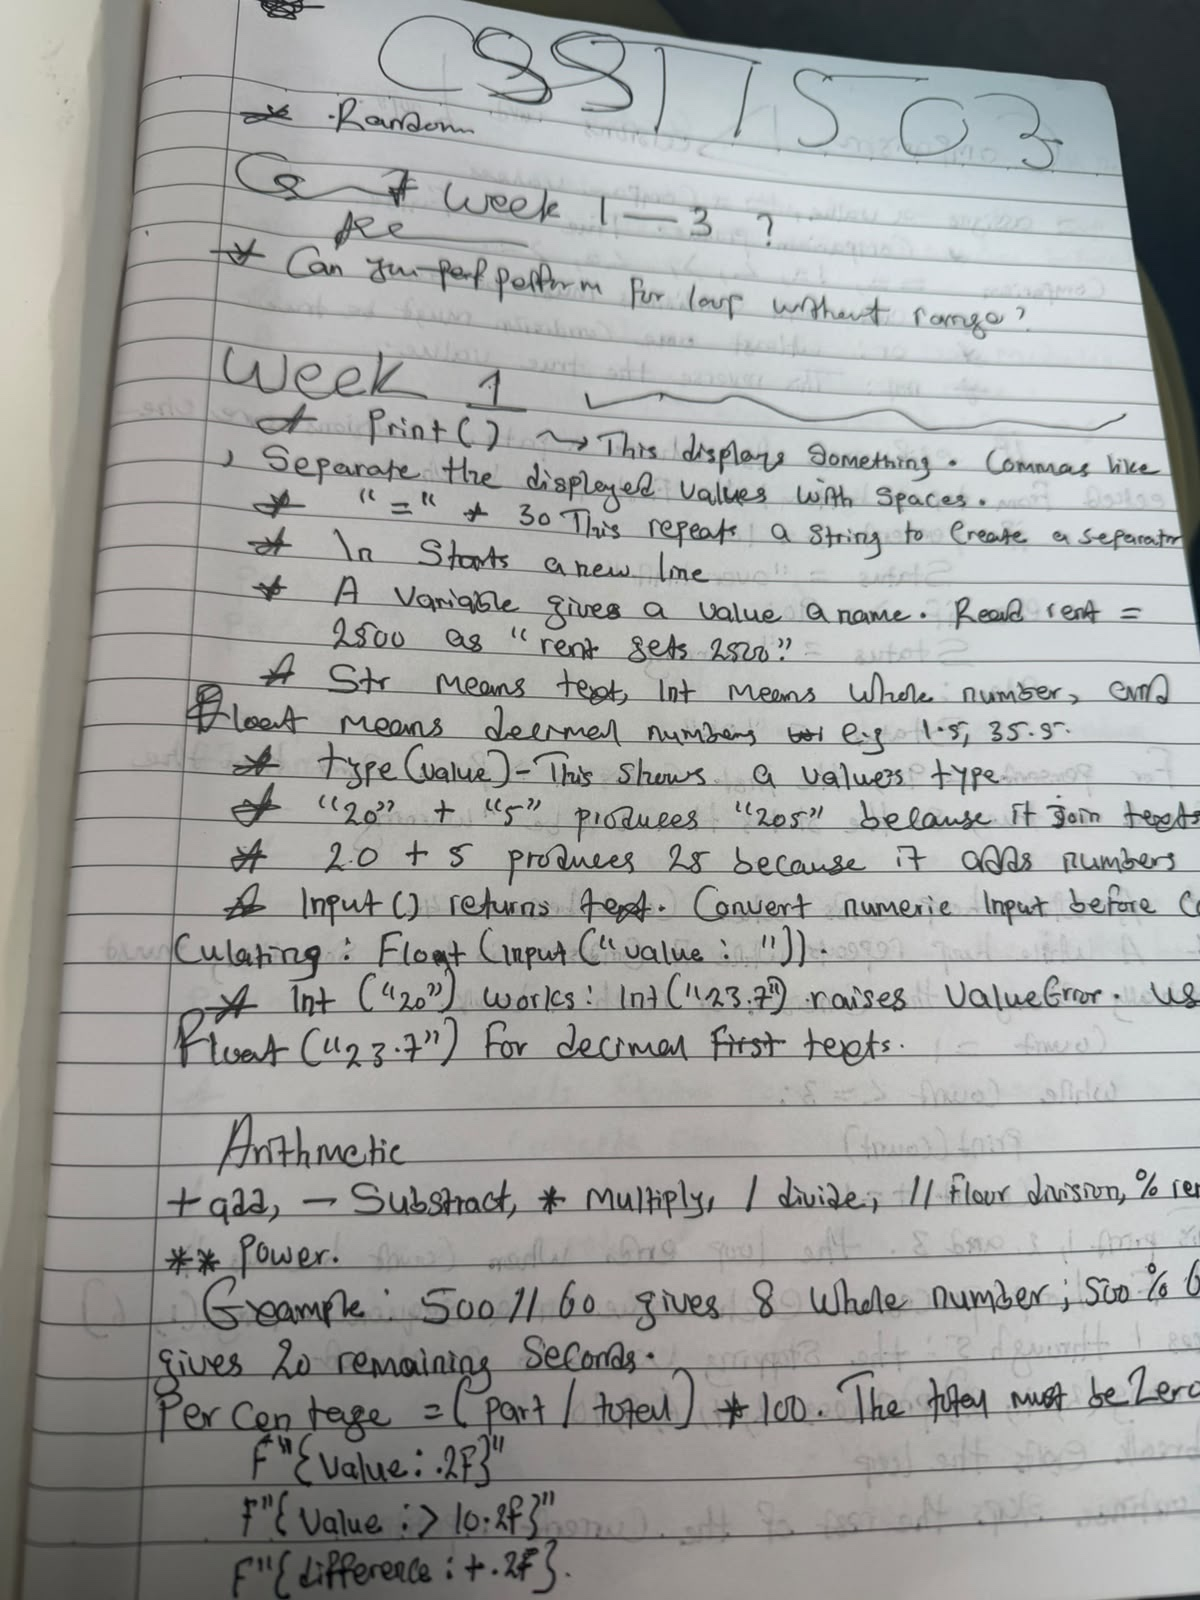

**Week 2 — Comparisons, decisions and loops**

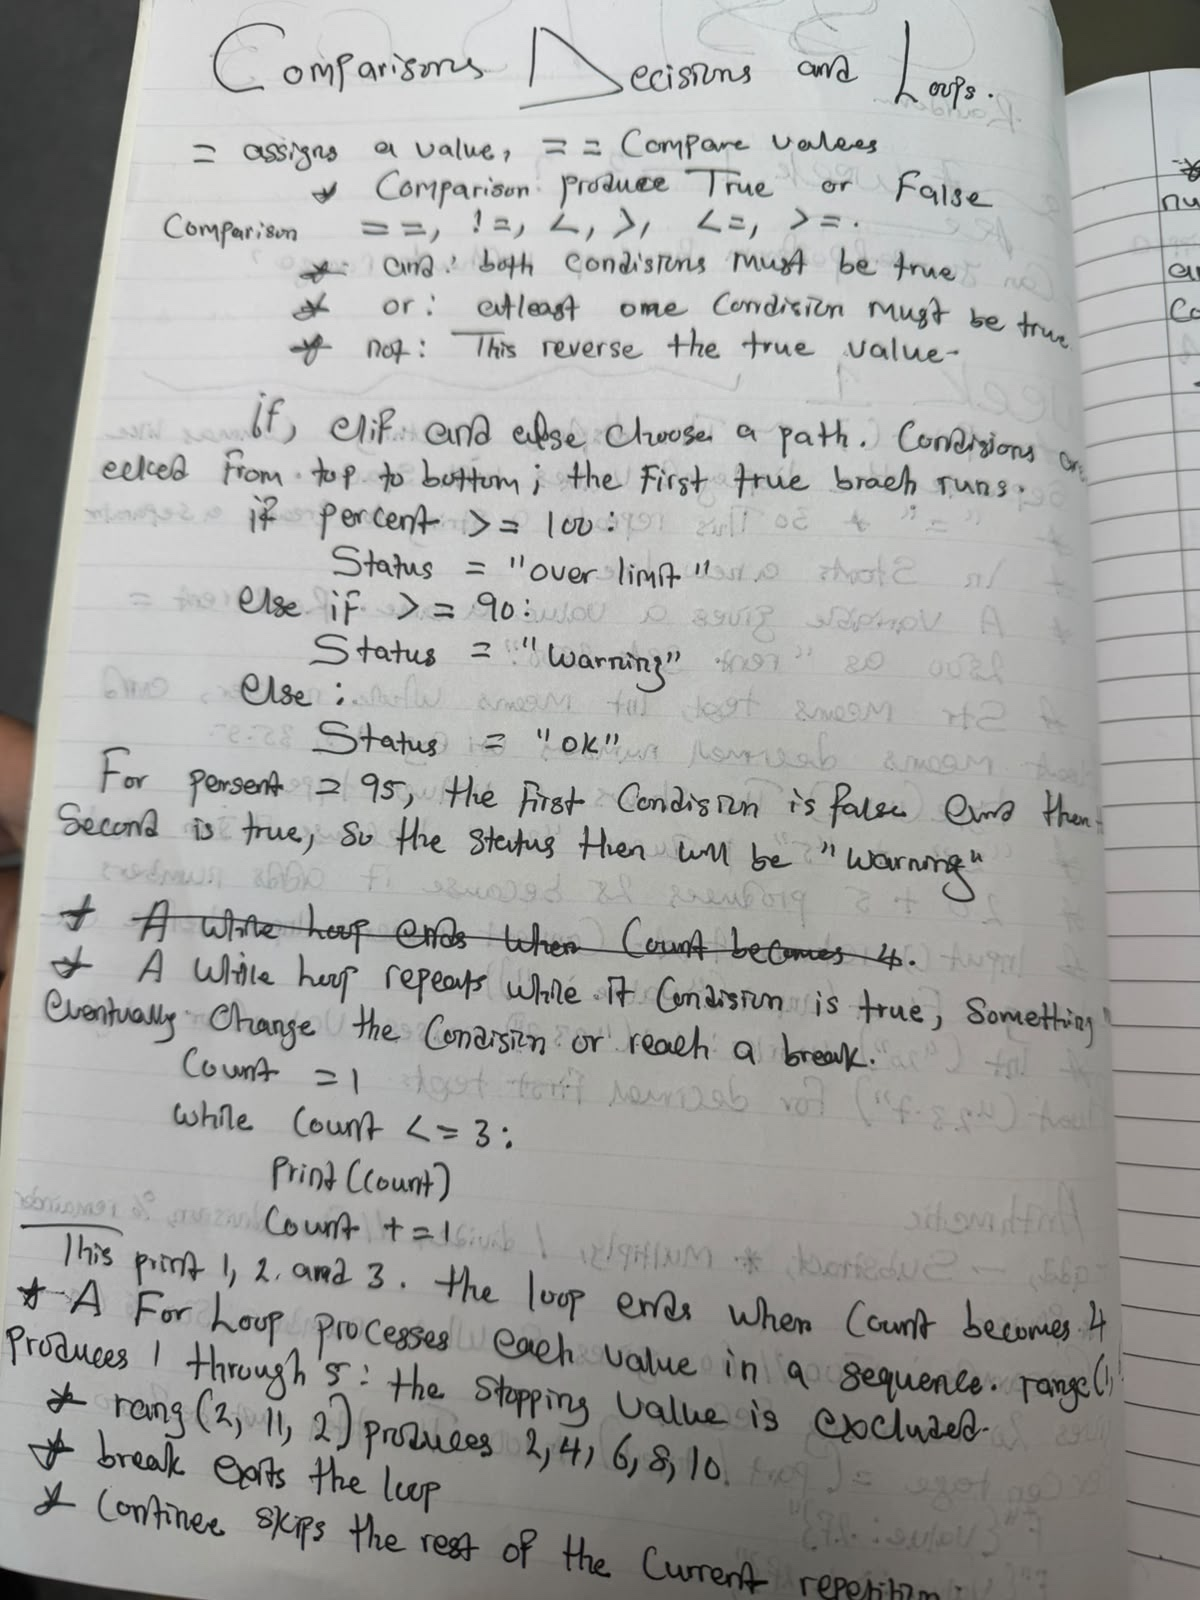

**Week 3 — Functions, arguments and scope**

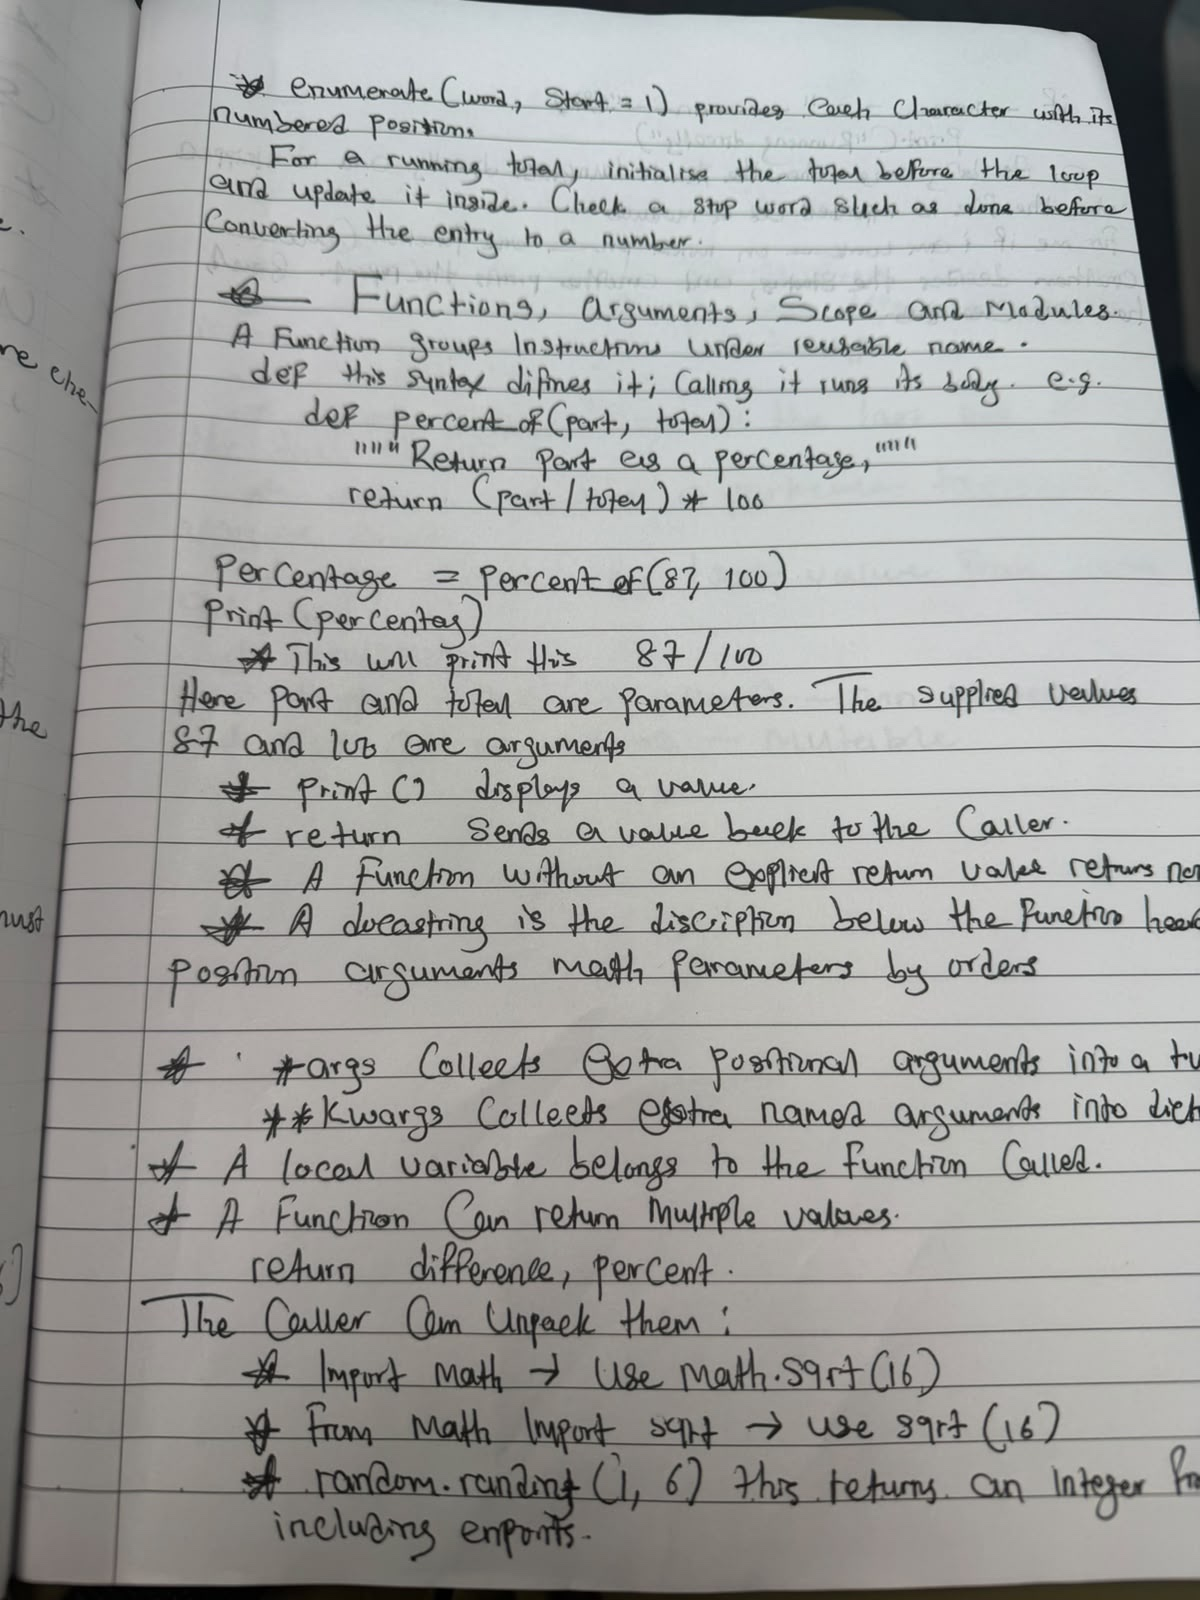

**Week 3 — Running and importing a module**

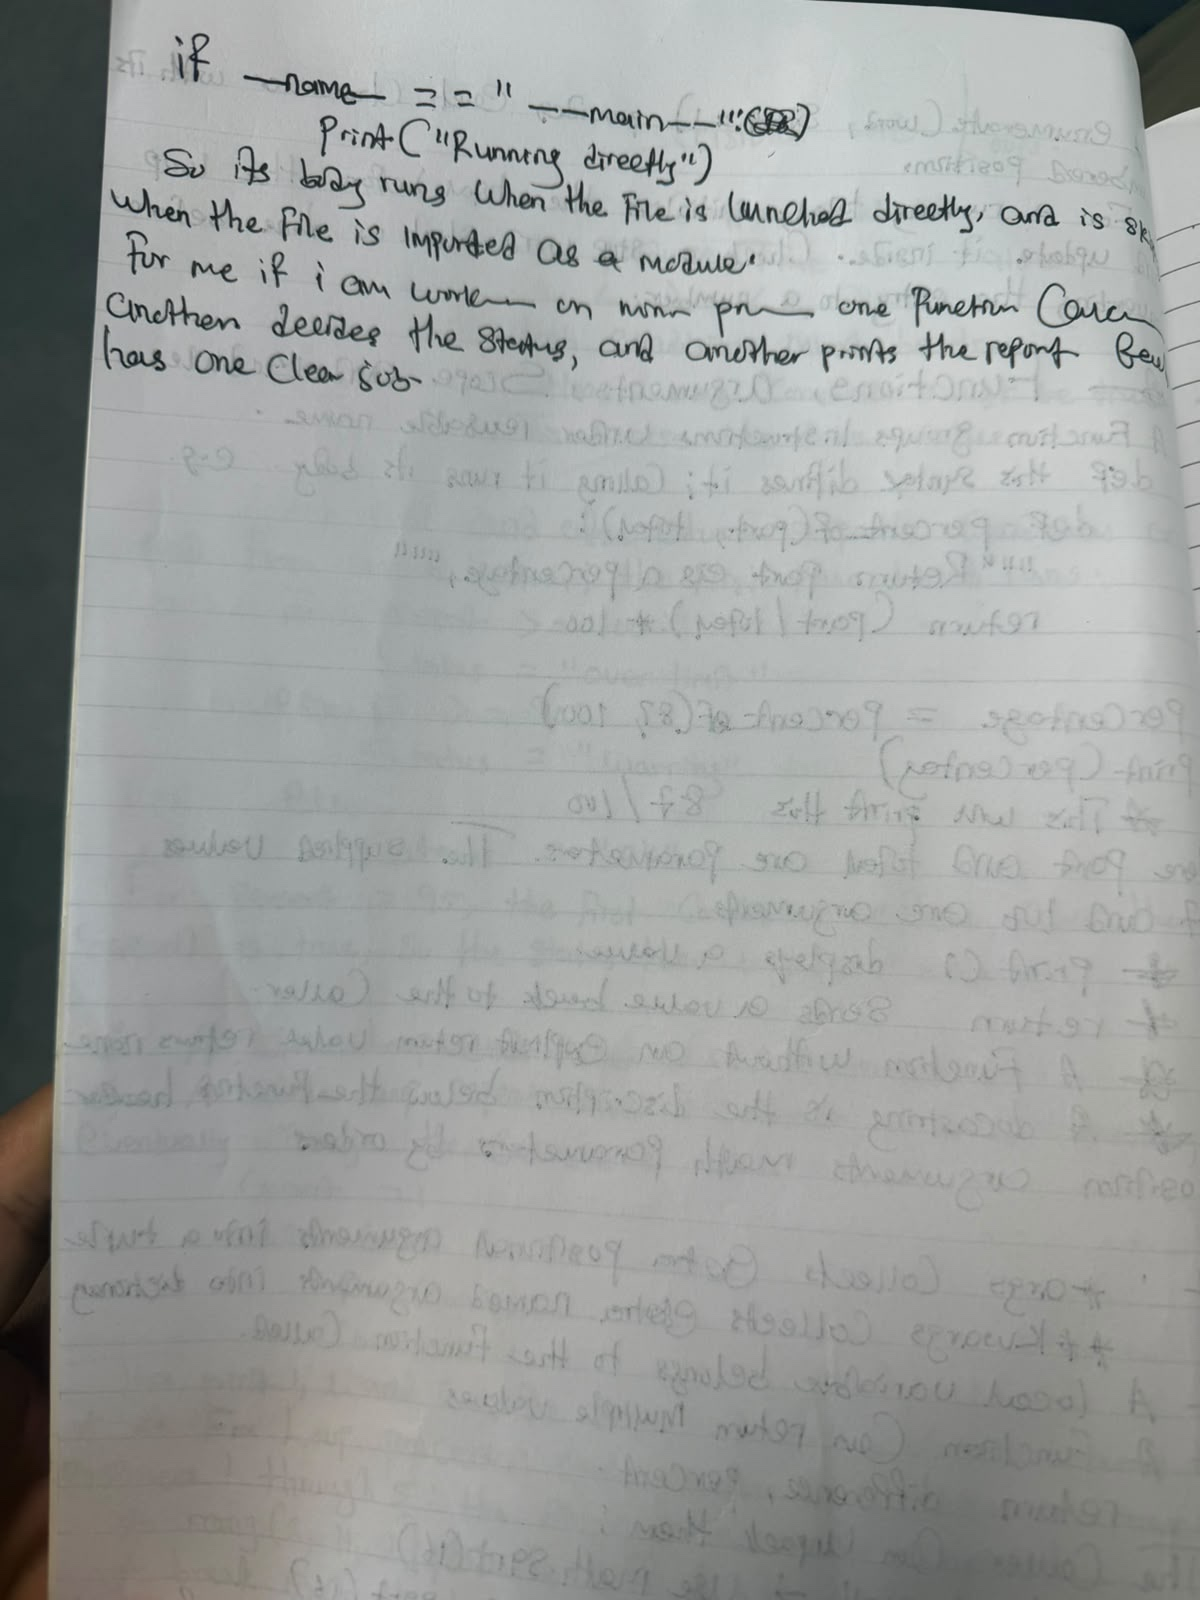

**Week 4 — Lists and tuples**

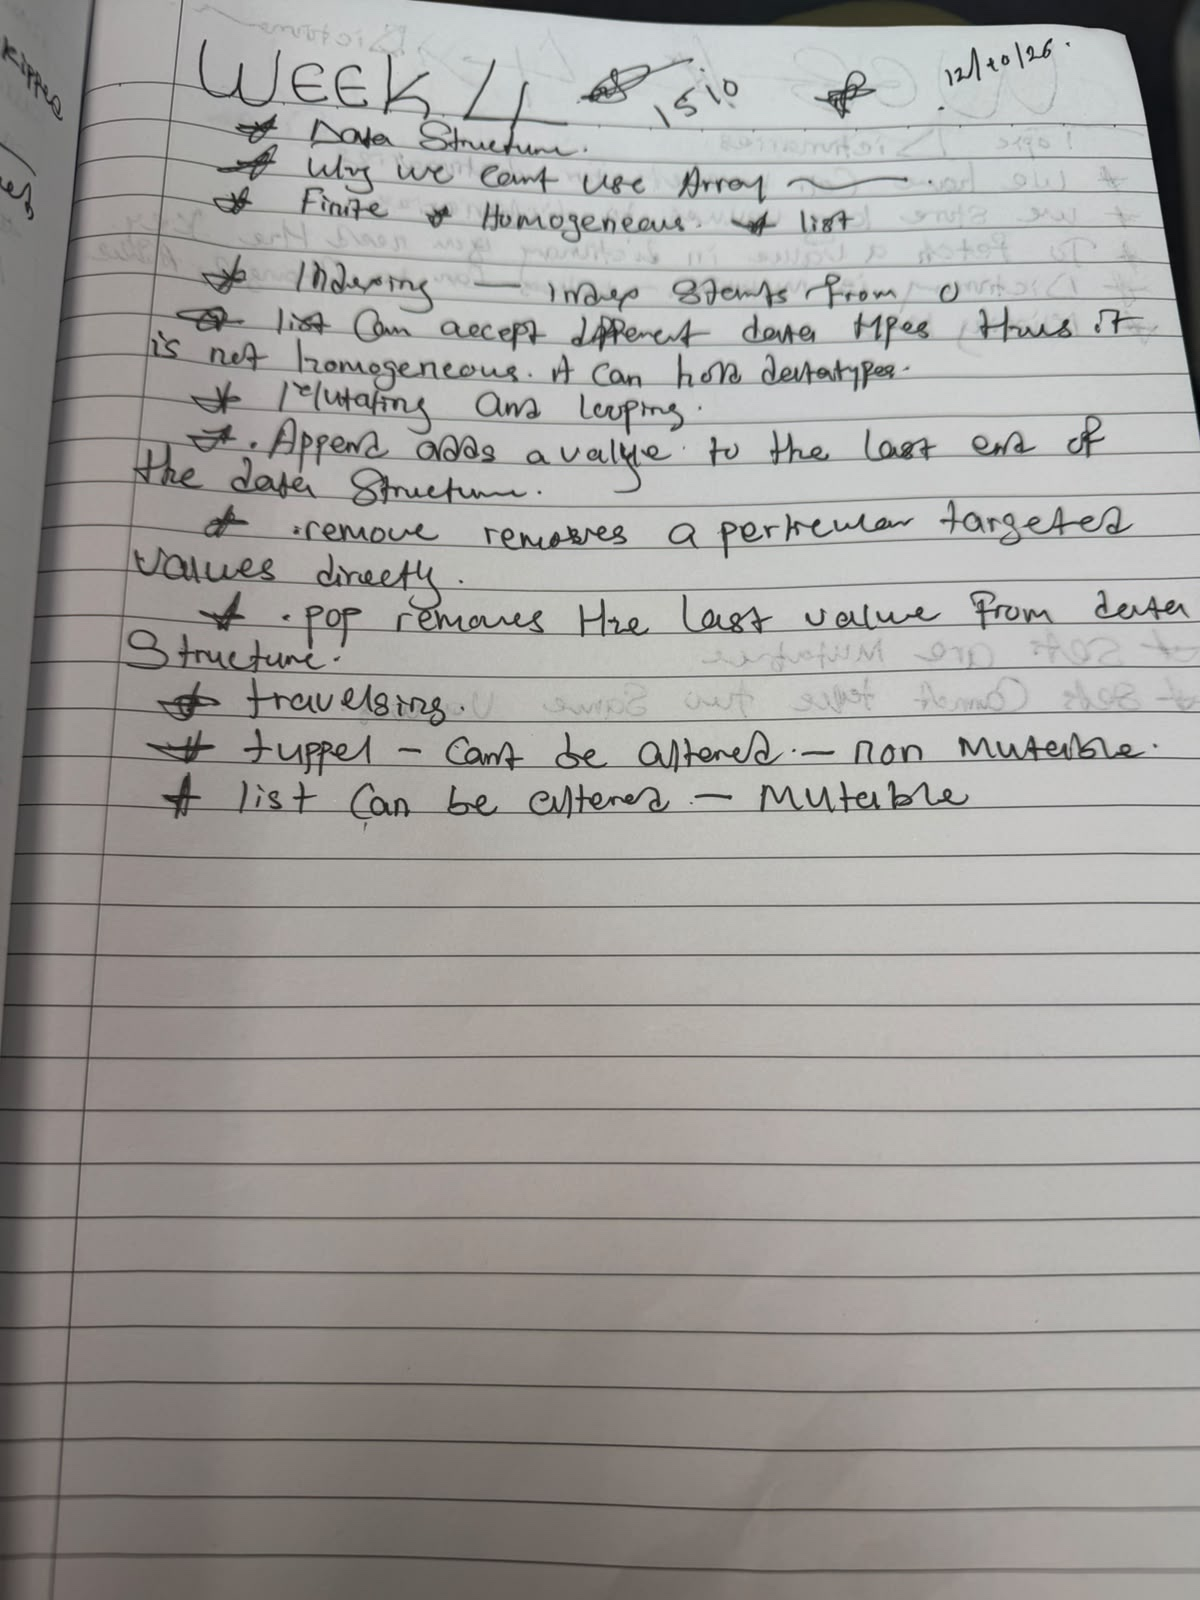

**Week 4 — Dictionaries and sets**

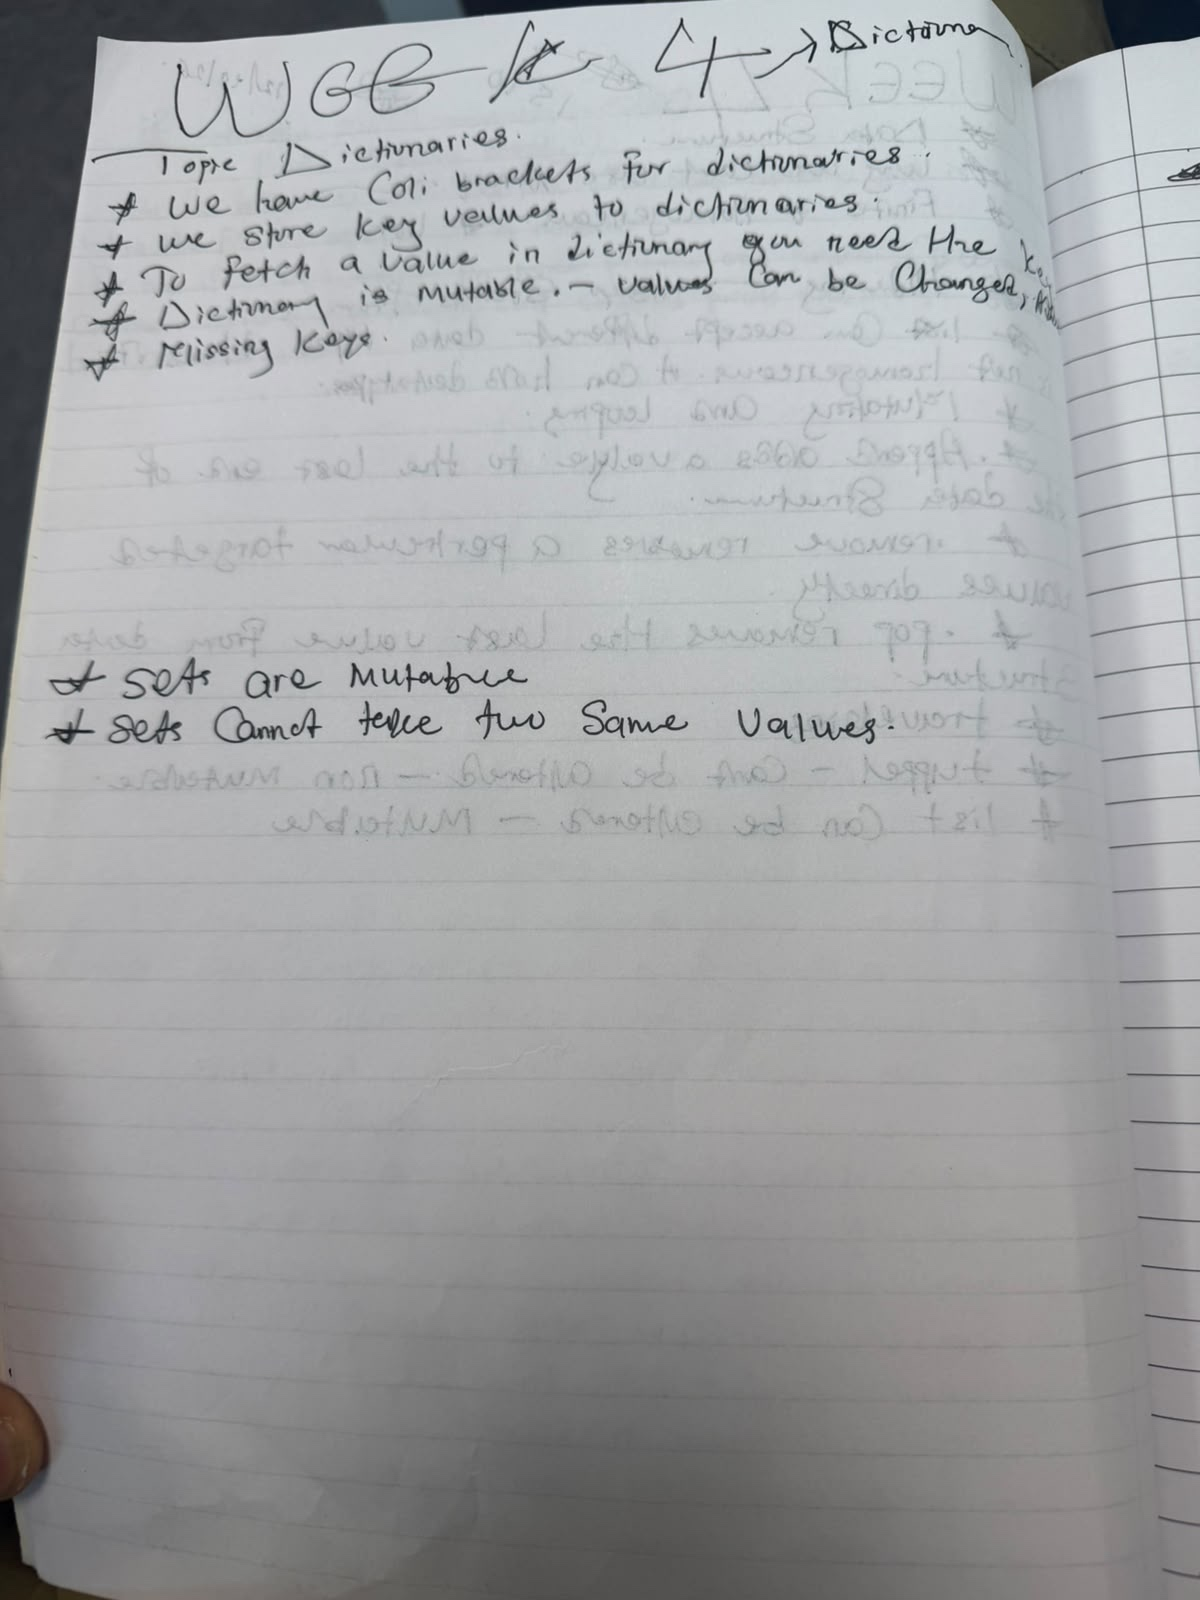

**Week 5 — Classes and objects**

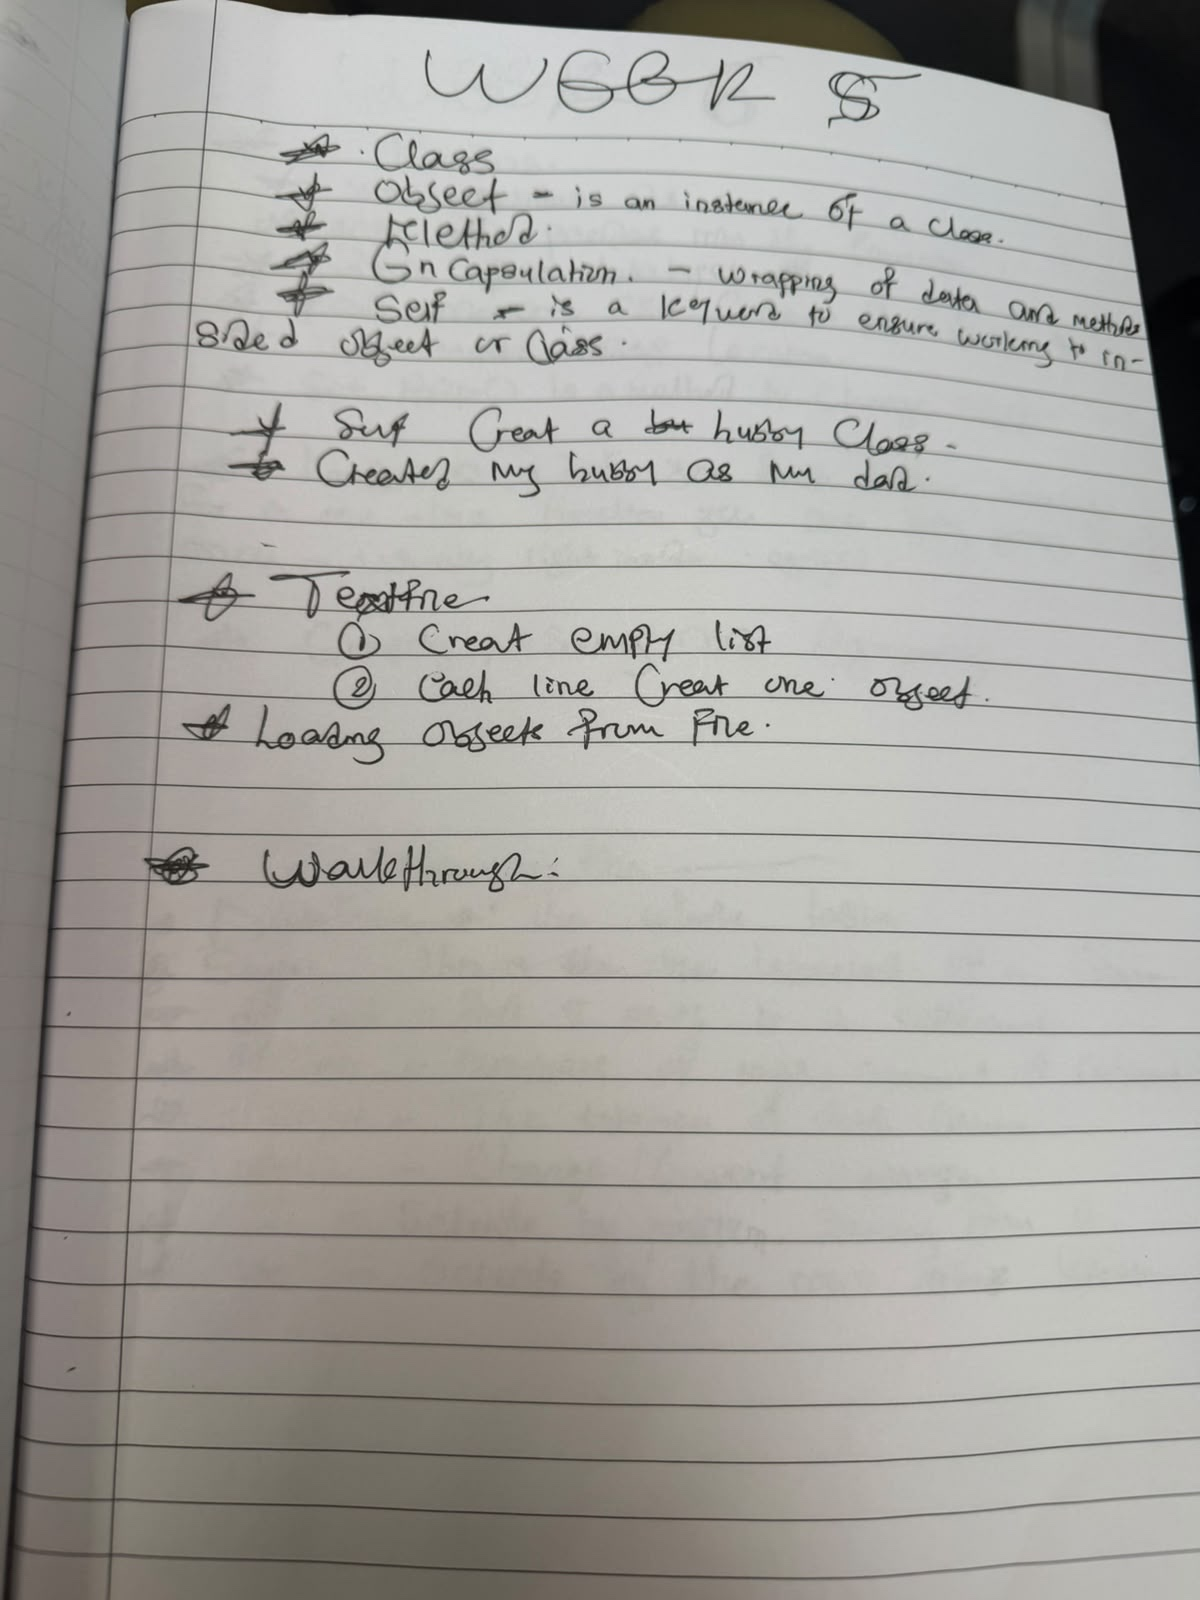


---
## 3. Push to GitHub

Save this notebook and `template.py`. Then open the `CST1510` folder in VS Code and run these
three commands in its terminal:

```
git add .
git commit -m "Week 5 lab and mini-project"
git push
```

Finally, open your repository on GitHub and check that this week's `LAB` folder is there.
If it is not, type `pwd` in the terminal to check which folder you are in.